# Phase 3E.01 — Portfolio Returns & Temporal Alignment

## 1. Research Objective

This notebook implements the first stage of the realistic backtesting framework for the 12-month Time-Series Momentum (TSMOM) strategy.

The objectives are to:

- Calculate monthly asset returns across the 16-ETF universe.
- Apply previously constructed portfolio weights to asset returns.
- Validate temporal alignment and prevent look-ahead bias.
- Calculate monthly gross portfolio returns before trading costs.
- Visualize portfolio returns and exposure characteristics.

The analysis uses the Train (2010–2017) and Validation (2018–2021) periods.

Historical observations from 2008–2009 are retained for momentum lookback and position initialization.

The Test period (2022–2025) remains untouched until Phase 3F.

In [63]:
from pathlib import Path
import sys

project_root = Path.cwd()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not (project_root / "src").is_dir():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import importlib
import src.data
import src.metrics
import src.research
import src.signals
import src.strategy

from src.data import prepare_monthly_prices
from src.strategy import build_tsmom_positions, calculate_portfolio_weights, calculate_portfolio_exposure

## 2. Data Preparation & Monthly Asset Returns

This section prepares the 16-ETF dataset using the reusable `prepare_monthly_prices()` function.

Monthly adjusted prices are retrieved for January 2008–December 2021 and converted into monthly returns using `pct_change()`.

Data quality checks verify dataset dimensions, missing values, and consistency before portfolio construction.

$$
r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1
$$

**Output:** $r_{i,t}$ is the return of ETF $i$ over month $t$, stored in `asset_returns`. $P_{i,t}$ and $P_{i,t-1}$ are its adjusted prices at consecutive month-ends (`monthly_prices`).

In [64]:
asset_universe = {
    "Equities" : ["SPY", "VGK", "EWJ", "EEM"],
    "Commodities" : ["USO", "DBA", "DBB", "DBC"],
    "Bonds" : ["IEF", "TLT", "LQD", "HYG"],
    "Forex" : ["FXE", "FXY", "FXB", "FXA"]
}

tickers = []

for assets in asset_universe.values():
    tickers.extend(assets)

start_date = "2008-01-01"
end_date = "2022-01-01"
lookback = 12

monthly_prices = prepare_monthly_prices(tickers, start_date, end_date)

print(monthly_prices.head())
print(monthly_prices.shape)
print(monthly_prices.isna().sum().sum())

asset_returns = monthly_prices.pct_change()

print(asset_returns.shape)
print(asset_returns.isna().sum().sum())
print(asset_returns.head())

Ticker            DBA        DBB        DBC        EEM        EWJ        FXA  \
Date                                                                           
2008-01-31  31.200174  19.611864  27.033495  30.937826  36.718540  65.858315   
2008-02-29  35.054859  21.755016  30.046463  31.554827  36.170078  68.784737   
2008-03-31  30.744696  20.388250  29.771803  30.370548  35.708210  67.721031   
2008-04-30  30.871218  20.388250  31.569603  33.145912  38.335094  70.257050   
2008-05-31  29.816866  19.385418  33.750256  34.194561  39.085617  71.677811   

Ticker             FXB         FXE         FXY        HYG        IEF  \
Date                                                                   
2008-01-31  173.245636  136.197601   93.910004  30.854921  56.444122   
2008-02-29  173.586060  139.362076   96.129997  30.278107  57.143620   
2008-03-31  174.066666  145.244644  100.239998  30.564577  57.907841   
2008-04-30  175.017456  144.052948   95.949997  31.602827  56.507935   
2008-05

## 3. Portfolio Position & Weight Reconstruction

This section reconstructs the 12-month TSMOM signals, lagged positions, and Equal Notional portfolio weights using the reusable functions developed in Phase 3D.

The resulting weights will be validated before calculating portfolio returns.

$$
p_{i,t}=s_{i,t-1},\qquad w_{i,t}=\frac{p_{i,t}}{N},\quad N=16
$$

**Notation and implementation.** $s_{i,t-1}$ is the preceding month-end signal, $p_{i,t}$ the held position (`positions`), $N=16$ the fixed ETF count, and $w_{i,t}$ the signed target weight stored in `portfolio_weights`.

In [65]:
signals, positions = build_tsmom_positions(monthly_prices, lookback=lookback)

portfolio_weights = calculate_portfolio_weights(positions)

print(portfolio_weights.shape)
print(portfolio_weights.isna().sum().sum())
print(portfolio_weights.dropna().head())

(168, 16)
208
Ticker         DBA     DBB     DBC     EEM     EWJ     FXA     FXB     FXE  \
Date                                                                         
2009-02-28 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625   
2009-03-31 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625   
2009-04-30 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625   
2009-05-31 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625   
2009-06-30 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625 -0.0625   

Ticker         FXY     HYG     IEF     LQD     SPY     TLT     USO     VGK  
Date                                                                        
2009-02-28  0.0625 -0.0625  0.0625 -0.0625 -0.0625  0.0625 -0.0625 -0.0625  
2009-03-31  0.0625 -0.0625  0.0625 -0.0625 -0.0625  0.0625 -0.0625 -0.0625  
2009-04-30  0.0625 -0.0625  0.0625 -0.0625 -0.0625  0.0625 -0.0625 -0.0625  
2009-05-31  0.0625 -0.0625  0.0625 -0.0625 -0.0625  0.

## 4. Temporal Alignment Validation

This section verifies the alignment of monthly asset returns and lagged portfolio weights.

Date and ticker consistency checks are performed to prevent incorrect return aggregation and look-ahead bias.

In [66]:
valid_dates = asset_returns.index.equals(portfolio_weights.index)
valid_tickers = asset_returns.columns.equals(portfolio_weights.columns)

print(positions.equals(signals.shift(1)))

print(valid_dates)
print(valid_tickers)

True
True
True


## 5. Gross Portfolio Returns

This section calculates the monthly gross returns of the TSMOM portfolio by combining lagged portfolio weights with monthly asset returns.

Returns are calculated before transaction costs and slippage, while preserving undefined initial observations.

Asset-level return contribution:

$$
c_{i,t}=w_{i,t}r_{i,t}
$$

$$
R_{p,t}^{gross}=\sum_{i=1}^{N}w_{i,t}r_{i,t}
$$

Weights are already lagged; do not shift them again. All 16 contributions must be defined for a valid portfolio return.

**Notation and implementation.** $w_{i,t}$ is the signed weight held over month $t$, $r_{i,t}$ its realized asset return, and $N=16$ the universe size. $c_{i,t}$ is the asset-level contribution (`weighted_returns`); $R_{p,t}^{gross}$ is the portfolio's total monthly return before trading frictions (`gross_portfolio_returns`).

In [67]:
weighted_returns = portfolio_weights * asset_returns

gross_portfolio_returns = weighted_returns.sum(axis=1, min_count=16)

print(gross_portfolio_returns.dropna().head())
print(gross_portfolio_returns.isna().sum())
print(gross_portfolio_returns.shape)

manual_returns = weighted_returns.loc["2009-02-28"].sum()
portfolio_return = gross_portfolio_returns.loc["2009-02-28"]

print(manual_returns)
print(portfolio_return)

print(np.isclose(manual_returns, portfolio_return))

Date
2009-02-28    0.037843
2009-03-31   -0.049798
2009-04-30   -0.054240
2009-05-31   -0.086176
2009-06-30    0.002079
Freq: ME, dtype: float64
13
(168,)
0.037842973916061465
0.037842973916061465
True


## 6. Reusable Portfolio Return Calculation

This section refactors the validated gross portfolio return calculation into a reusable function.

The function will aggregate monthly weighted asset returns while preserving undefined initial observations.

In [68]:
importlib.reload(src.strategy)

from src.strategy import calculate_gross_portfolio_returns

asset_returns_fn, weighted_returns_fn, gross_returns_fn = calculate_gross_portfolio_returns(monthly_prices, portfolio_weights)

print(asset_returns_fn.equals(asset_returns))
print(weighted_returns_fn.equals(weighted_returns))
print(gross_returns_fn.equals(gross_portfolio_returns))

True
True
True


## 7. Visual Analysis

This section visualizes monthly gross portfolio returns and exposure characteristics across the Train and Validation periods.

The objective is to identify performance patterns and portfolio behavior before transaction costs and slippage.

$$
G_t=\sum_{i=1}^{N}|w_{i,t}|,\qquad E_t=\sum_{i=1}^{N}w_{i,t},\qquad |E_t|\le G_t\le 1
$$

**Outputs:** $G_t$ is gross exposure (`gross_exposure`), and $E_t$ is signed net exposure (`net_exposure`), calculated from $w_{i,t}$, the target portfolio weights. The displayed series are `plot_gross_exposure` and `plot_net_exposure`.

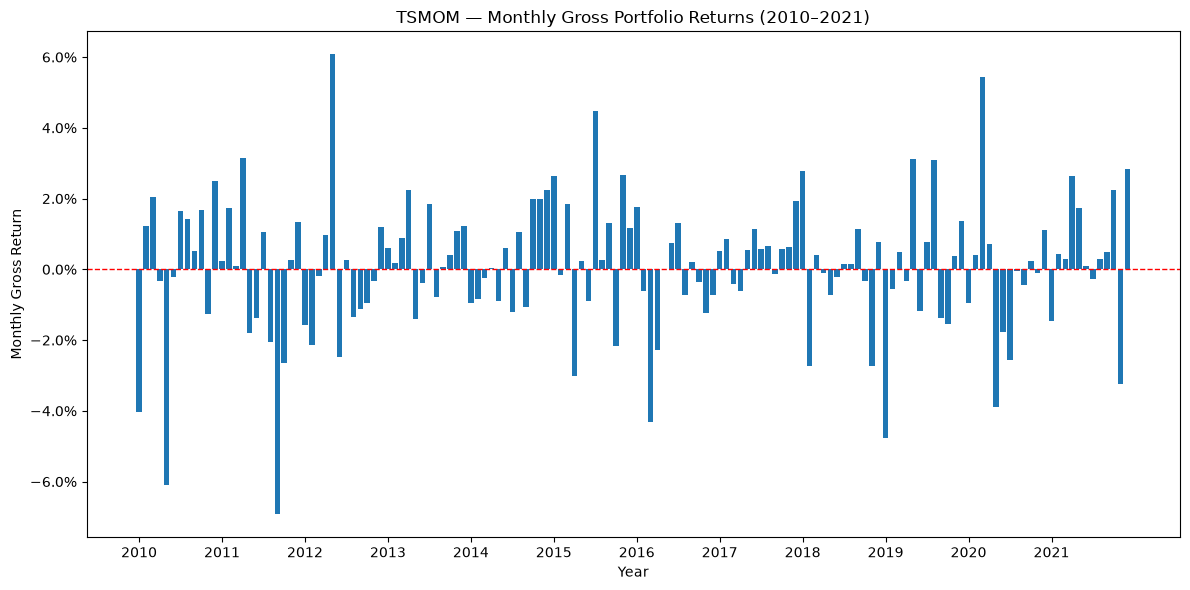

Date
2010-01-31    1.0
2010-02-28    1.0
2010-03-31    1.0
2010-04-30    1.0
2010-05-31    1.0
Freq: ME, dtype: float64
Date
2010-01-31    0.625
2010-02-28    0.625
2010-03-31    0.875
2010-04-30    0.625
2010-05-31    0.750
Freq: ME, dtype: float64


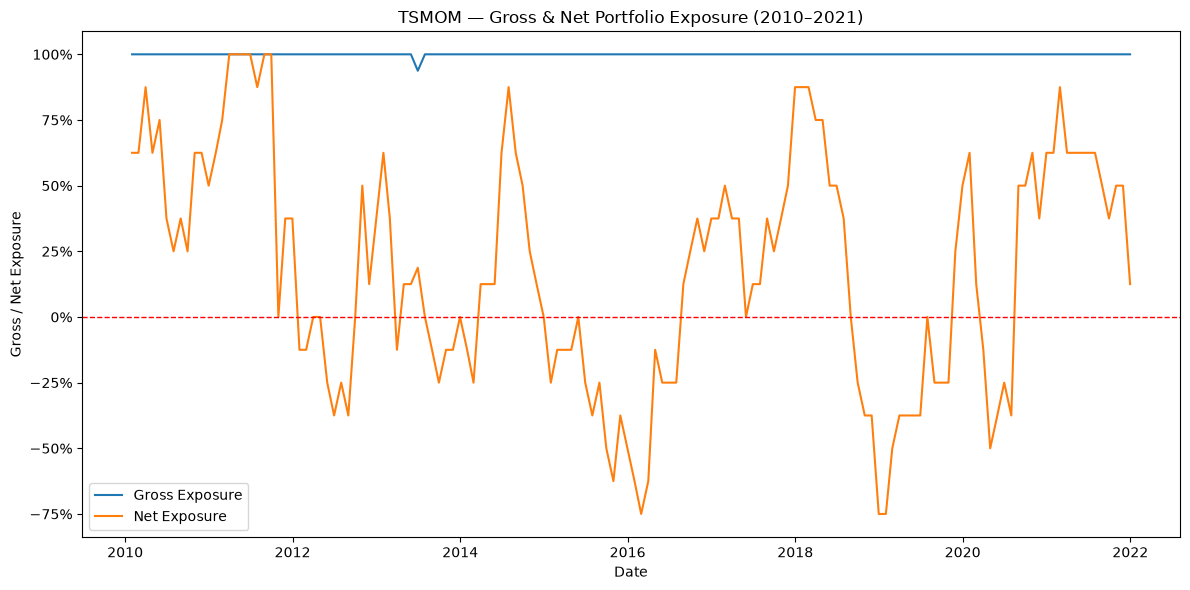

In [69]:
from matplotlib.ticker import PercentFormatter

plot_returns = gross_portfolio_returns.loc["2010-01-01":"2021-12-31"]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(plot_returns))

ax.bar(x, plot_returns.values, width=0.8)

ax.set_xticks(x[::12])
ax.set_xticklabels(plot_returns.index[::12].strftime("%Y"), rotation=0)

ax.set_title("TSMOM — Monthly Gross Portfolio Returns (2010–2021)")
ax.set_xlabel("Year")
ax.set_ylabel("Monthly Gross Return")
ax.axhline(0, color="red", linestyle="--", linewidth=1)

ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()




gross_exposure, net_exposure = calculate_portfolio_exposure(portfolio_weights)

plot_gross_exposure = gross_exposure.loc["2010-01-01":"2021-12-31"]
plot_net_exposure = net_exposure.loc["2010-01-01":"2021-12-31"]

print(plot_gross_exposure.head())
print(plot_net_exposure.head())

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(plot_gross_exposure.index, plot_gross_exposure, label="Gross Exposure")
ax.plot(plot_net_exposure.index, plot_net_exposure, label="Net Exposure")

ax.set_title("TSMOM — Gross & Net Portfolio Exposure (2010–2021)")
ax.set_ylabel("Gross / Net Exposure")
ax.set_xlabel("Date")

plt.axhline(0, color="red", linestyle="--", linewidth=1)
ax.legend()
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

# Verification du mois ou Gross Exposure =/ 100%

# print(plot_gross_exposure[plot_gross_exposure < 1])

# flat_count = positions.eq(0).sum(axis=1)

# print(flat_count.loc[plot_gross_exposure[plot_gross_exposure < 1].index])

## 8. Final Validation & Conclusion

This section performs final consistency checks on portfolio returns and exposures.

The objective is to confirm data integrity, temporal alignment, and consistency with the portfolio construction rules before proceeding to performance analysis.

In [70]:
print(gross_portfolio_returns.loc["2010":"2021"].shape)
print(gross_portfolio_returns.loc["2010":"2021"].isna().sum())

(144,)
0


### Conclusion — Portfolio Returns & Temporal Alignment

The 12-month TSMOM strategy's gross portfolio returns were successfully calculated across 16 ETFs using lagged Equal Notional portfolio weights.

Validation confirmed:
- Correct alignment of asset returns and portfolio weights.
- Preservation of the 13 initial undefined observations.
- Consistency between manual and vectorized return calculations.
- 144 monthly observations without missing values across Train and Validation.

Visual analysis includes monthly gross returns and gross/net portfolio exposures.

The results represent gross returns before transaction costs and slippage. Economic performance and risk-adjusted metrics have not yet been evaluated.

**Next step:** Phase 3E.02 — Performance & Risk Analysis.